# 01 · Exploratory Data Analysis: what drives an IPO's listing-day gain?

**Data:** 634 Indian mainboard IPOs, 2010–2026 (REITs, InvITs, FPOs removed).
**Target:** listing-day gain = listing-day open / offer price − 1, in %.
499 targets are verified against the NSE open (split-restored, via Yahoo Finance); 135 come from
Kaggle only and are flagged `kaggle_unverified`. See `reports/data_audit.md`.

Every feature here is knowable **before** listing: subscription closes before listing, and market
features use data up to 7 days before the listing date.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.config import PROCESSED_DIR
from src.viz import AQUA, BLUE, GAIN, LOSS, NEUTRAL, TEXT_SECONDARY, apply_style, save

apply_style()
pd.set_option("display.float_format", "{:.2f}".format)

df = pd.read_csv(PROCESSED_DIR / "ipo_features.csv", parse_dates=["listing_date"])
gain = df["target_gain_pct"]
print(f"{len(df)} IPOs, {df.listing_date.min():%b %Y} to {df.listing_date.max():%b %Y}")
df.head()

634 IPOs, Jan 2010 to May 2026


,ipo_id,ipo_name,symbol,listing_date,sub_qib,sub_hni,sub_rii,sub_total,issue_size_cr,offer_price,...,fully_subscribed,log_issue_size,log_offer_price,nifty_ret_1w,nifty_ret_1m,nifty_ret_3m,nifty_vs_200dma,vix,recent_ipo_count,recent_ipo_mean_gain
0,IPO0001,JSW Energy Limited,JSWENERGY,2010-01-04,2.88,0.15,0.40,1.68,2700.00,100.00,...,1,7.90,4.61,2.71,1.38,4.07,19.27,22.69,0,NaN
1,IPO0002,Godrej Properties Limited,GODREJPROP,2010-01-05,7.45,0.41,0.38,4.00,468.85,490.00,...,1,6.15,6.19,4.01,3.64,3.34,19.15,24.41,0,NaN
2,IPO0003,D B Corp Limited,DBCORP,2010-01-06,68.52,26.17,3.42,39.54,384.22,212.00,...,1,5.95,5.36,4.38,4.61,4.01,18.38,24.62,0,NaN
3,IPO0004,MBL Infrastructure Limited,MBLINFRA,2010-01-11,3.35,2.65,0.40,1.97,102.60,180.00,...,1,4.63,5.19,1.70,2.15,5.51,19.10,23.64,0,NaN
4,IPO0005,Birla Shloka Edutech Limited,NaN,2010-01-29,0.00,5.45,1.76,1.43,34.78,50.00,...,1,3.55,3.91,-4.12,1.68,-0.55,10.41,24.85,4,6.39


## 1. The target: how do IPOs list?

In [2]:
summary = pd.Series({
    "Median gain %": gain.median(),
    "Mean gain %": gain.mean(),
    "Listed below offer price %": (gain < 0).mean() * 100,
    "Listed flat (0%) %": (gain == 0).mean() * 100,
    "Gain above 15% %": (gain > 15).mean() * 100,
    "Gain above 50% %": (gain > 50).mean() * 100,
})
summary.round(1).to_frame("value")

,value
Median gain %,6.60
Mean gain %,16.80
Listed below offer price %,25.20
Listed flat (0%) %,6.30
Gain above 15% %,34.20
Gain above 50% %,11.50


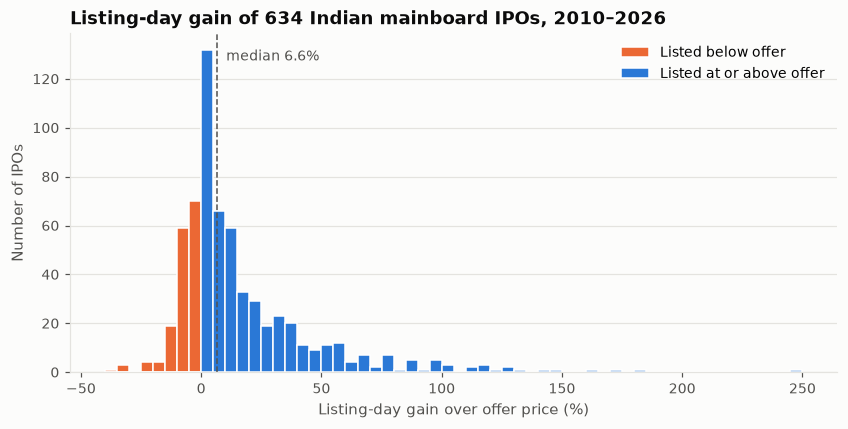

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(-40, 255, 5)
ax.hist(gain[gain < 0], bins=bins, color=LOSS, edgecolor="white", linewidth=1, label="Listed below offer")
ax.hist(gain[gain >= 0], bins=bins, color=GAIN, edgecolor="white", linewidth=1, label="Listed at or above offer")
ax.axvline(gain.median(), color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.annotate(f"median {gain.median():.1f}%", (gain.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=TEXT_SECONDARY, fontsize=9)
ax.set_title("Listing-day gain of 634 Indian mainboard IPOs, 2010–2026")
ax.set_xlabel("Listing-day gain over offer price (%)")
ax.set_ylabel("Number of IPOs")
ax.legend(loc="upper right")
save(fig, "01_gain_distribution")
plt.show()

Skewed to the right: a typical IPO lists only a few percent up, while a long tail of very hot
issues pulls the mean well above the median. This is why the model should predict a **range**,
and why median-based metrics (MAE) suit it better than RMSE alone.

## 2. Hot and cold years

In [4]:
by_year = df.groupby("year").agg(ipos=("ipo_id", "count"), median_gain=("target_gain_pct", "median"),
                                 share_loss=("target_gain_pct", lambda s: (s < 0).mean() * 100))
by_year

,ipos,median_gain,share_loss
year,,,
2010,74,5.37,21.62
2011,39,1.23,35.90
2012,11,1.45,36.36
2013,4,4.90,25.00
2014,6,16.94,33.33
2015,19,2.38,36.84
2016,27,9.59,25.93
2017,36,5.95,22.22
2018,24,1.35,45.83


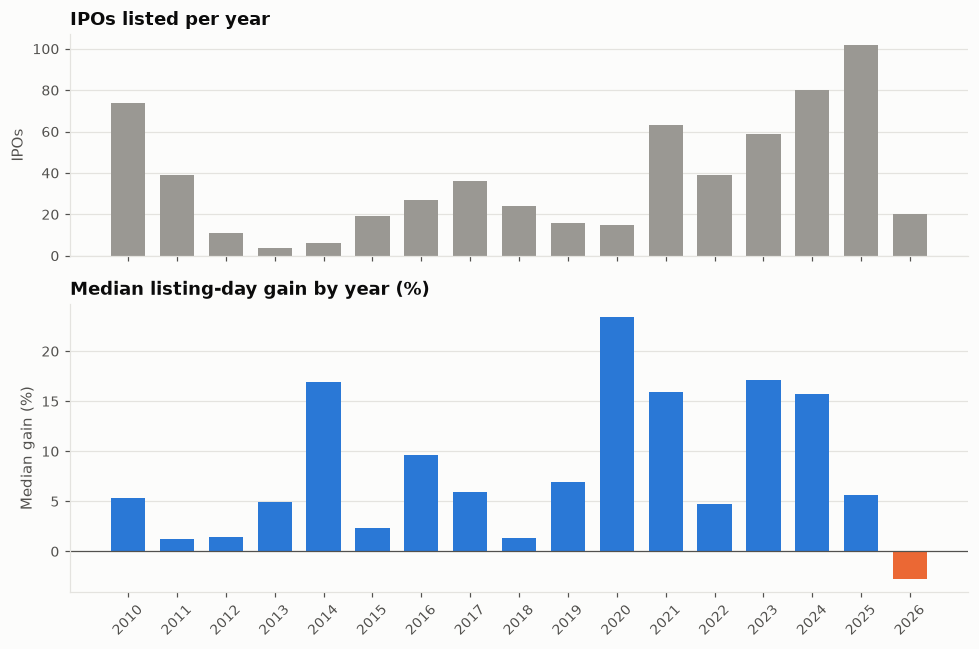

In [5]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
top.bar(by_year.index, by_year["ipos"], color=NEUTRAL, width=0.7)
top.set_title("IPOs listed per year")
top.set_ylabel("IPOs")
colors = [GAIN if v >= 0 else LOSS for v in by_year["median_gain"]]
bottom.bar(by_year.index, by_year["median_gain"], color=colors, width=0.7)
bottom.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
bottom.set_title("Median listing-day gain by year (%)")
bottom.set_ylabel("Median gain (%)")
bottom.set_xticks(by_year.index)
bottom.tick_params(axis="x", rotation=45)
fig.tight_layout()
save(fig, "02_by_year")
plt.show()

IPO activity and listing gains move in waves. Quiet years (2012–14) were followed by busy ones
(2021, 2024–25). A random train/test split would mix these regimes; the model will be trained on
earlier years and tested on later ones.

## 3. Subscription: the strongest signal

In [6]:
bucket_edges = [0, 1, 3, 10, 30, 100, 1e5]
bucket_labels = ["<1x", "1–3x", "3–10x", "10–30x", "30–100x", "100x+"]
df["sub_bucket"] = pd.cut(df["sub_total"], bucket_edges, labels=bucket_labels)
by_bucket = df.groupby("sub_bucket", observed=True)["target_gain_pct"].agg(
    ipos="count", median="median", mean="mean",
    p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75),
    share_positive=lambda s: (s > 0).mean() * 100,
)
by_bucket

,ipos,median,mean,p25,p75,share_positive
sub_bucket,,,,,,
<1x,26,0.00,0.58,-5.47,3.01,38.46
1–3x,177,0.00,-1.10,-5.98,2.38,41.24
3–10x,104,3.88,3.54,-2.03,9.27,61.54
10–30x,90,9.92,11.02,0.00,18.23,70.00
30–100x,164,23.26,29.06,9.85,43.09,92.07
100x+,73,56.56,64.47,33.33,87.50,100.00


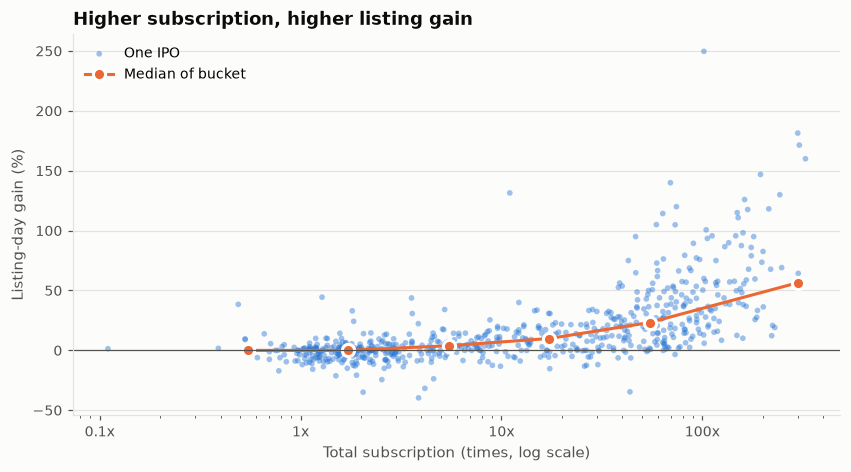

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(df["sub_total"], gain, s=14, color=BLUE, alpha=0.45, edgecolor="none", label="One IPO")
centers = [np.sqrt(max(lo, 0.3) * hi) if hi < 1e5 else 300 for lo, hi in zip(bucket_edges[:-1], bucket_edges[1:])]
ax.plot(centers, by_bucket["median"], color=LOSS, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="Median of bucket")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_title("Higher subscription, higher listing gain")
ax.set_xlabel("Total subscription (times, log scale)")
ax.set_ylabel("Listing-day gain (%)")
ax.legend(loc="upper left")
save(fig, "03_subscription_vs_gain")
plt.show()

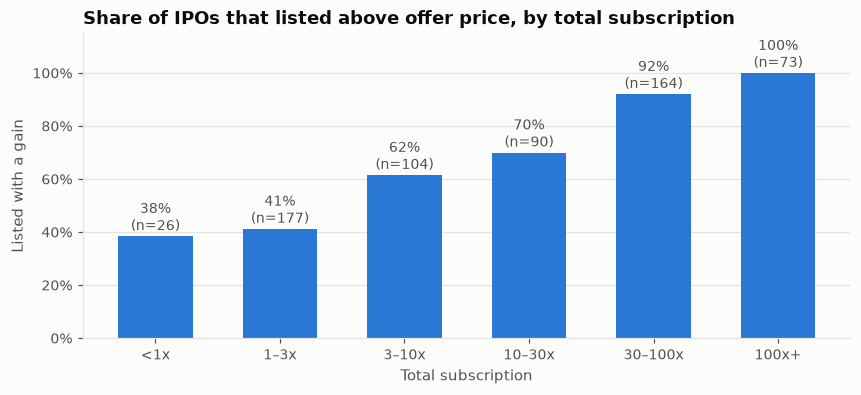

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(by_bucket.index.astype(str), by_bucket["share_positive"], color=BLUE, width=0.6)
for x, (share, n) in enumerate(zip(by_bucket["share_positive"], by_bucket["ipos"])):
    ax.annotate(f"{share:.0f}%\n(n={n})", (x, share), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_ylim(0, 115)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Share of IPOs that listed above offer price, by total subscription")
ax.set_xlabel("Total subscription")
ax.set_ylabel("Listed with a gain")
save(fig, "04_hit_rate_by_subscription")
plt.show()

Below 3x, an IPO is closer to a coin toss (often listing flat). Above 30x, more than nine in ten
list with a gain. The popular "apply if subscribed over 30x" rule is real, so it becomes the
**baseline the model has to beat**.

## 4. Which investor category carries the signal?

In [9]:
feature_names = {
    "log_sub_total": "Total subscription", "log_sub_hni": "HNI / NII subscription",
    "log_sub_qib": "QIB subscription", "log_sub_rii": "Retail subscription",
    "qib_to_rii": "QIB relative to retail", "nifty_ret_3m": "NIFTY return, 3 months",
    "nifty_vs_200dma": "NIFTY vs 200-day average", "nifty_ret_1m": "NIFTY return, 1 month",
    "recent_ipo_mean_gain": "Recent IPOs' mean gain (90 days)", "nifty_ret_1w": "NIFTY return, 1 week",
    "log_offer_price": "Offer price (log)", "recent_ipo_count": "IPOs in last 90 days",
    "log_issue_size": "Issue size (log)", "vix": "India VIX",
}
corr = (df[list(feature_names) + ["target_gain_pct"]].corr(method="spearman")["target_gain_pct"]
        .drop("target_gain_pct").rename(index=feature_names).sort_values())
corr.to_frame("Spearman correlation with gain")

,Spearman correlation with gain
India VIX,-0.11
Issue size (log),-0.02
IPOs in last 90 days,-0.02
Offer price (log),0.03
"NIFTY return, 1 week",0.05
Recent IPOs' mean gain (90 days),0.12
"NIFTY return, 1 month",0.20
NIFTY vs 200-day average,0.20
"NIFTY return, 3 months",0.23
QIB relative to retail,0.31


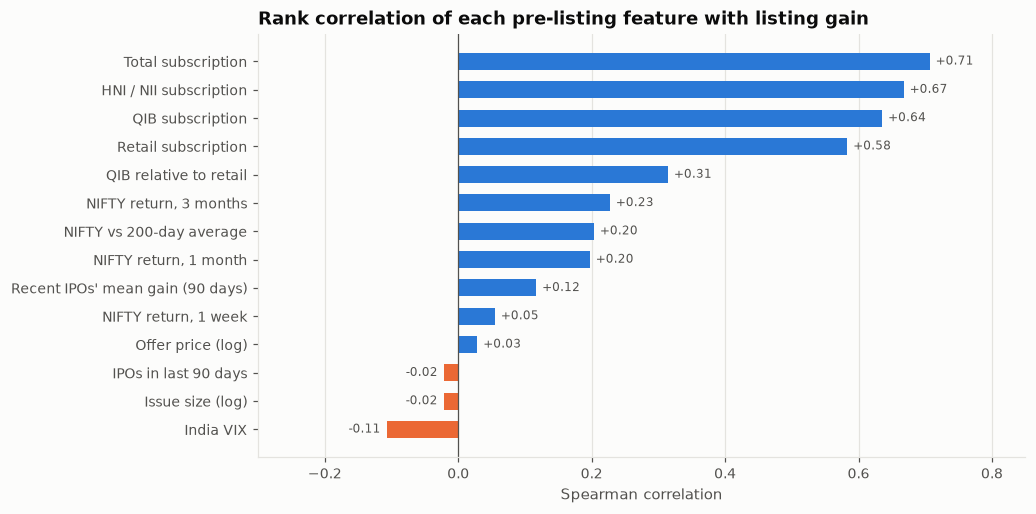

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = [GAIN if v >= 0 else LOSS for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=0.6)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
for y, v in enumerate(corr.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=8, color=TEXT_SECONDARY)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(-0.3, 0.85)
ax.set_title("Rank correlation of each pre-listing feature with listing gain")
ax.set_xlabel("Spearman correlation")
save(fig, "05_feature_correlation")
plt.show()

HNI (non-institutional) and QIB demand track listing gains more closely than retail demand.
Subscription categories are strongly correlated with each other, so the model will see some
redundancy; tree models and regularised linear models handle that differently, and we compare both.

## 5. Market mood

In [11]:
df["market"] = np.where(df["nifty_vs_200dma"] >= 0, "NIFTY above 200-day avg", "NIFTY below 200-day avg")
df["heat"] = pd.qcut(df["recent_ipo_mean_gain"], 3, labels=["Cold IPO market", "Normal", "Hot IPO market"])
mood = pd.concat([
    df.groupby("market")["target_gain_pct"].agg(ipos="count", median="median", share_positive=lambda s: (s > 0).mean() * 100),
    df.groupby("heat", observed=True)["target_gain_pct"].agg(ipos="count", median="median", share_positive=lambda s: (s > 0).mean() * 100),
])
mood

,ipos,median,share_positive
NIFTY above 200-day avg,518,7.89,70.08
NIFTY below 200-day avg,116,2.94,61.21
Cold IPO market,207,5.18,67.63
Normal,209,5.06,67.46
Hot IPO market,206,9.92,69.42


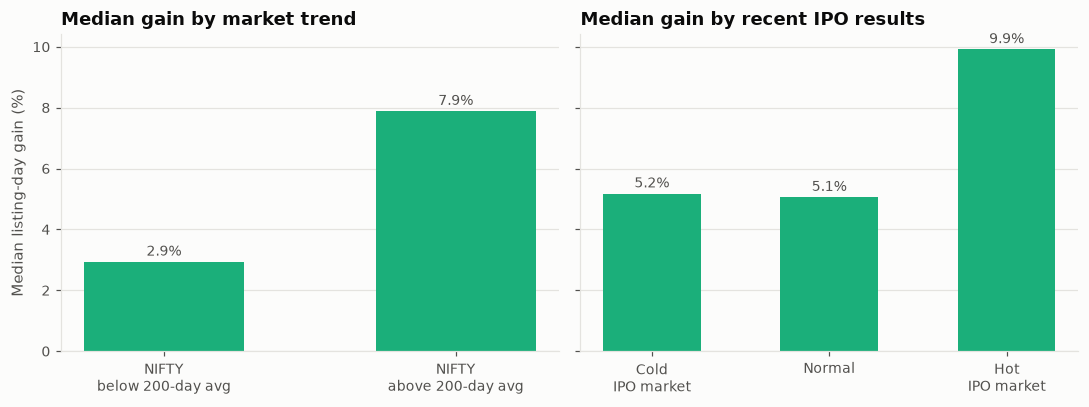

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, column, order in [
    (axes[0], "market", ["NIFTY below 200-day avg", "NIFTY above 200-day avg"]),
    (axes[1], "heat", ["Cold IPO market", "Normal", "Hot IPO market"]),
]:
    medians = df.groupby(column, observed=True)["target_gain_pct"].median().reindex(order)
    ax.bar([label.replace(" ", "\n", 1) for label in order], medians.values, color=AQUA, width=0.55)
    for x, v in enumerate(medians.values):
        ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 4), textcoords="offset points", ha="center",
                    fontsize=9, color=TEXT_SECONDARY)
axes[0].set_title("Median gain by market trend")
axes[1].set_title("Median gain by recent IPO results")
axes[0].set_ylabel("Median listing-day gain (%)")
fig.tight_layout()
save(fig, "06_market_mood")
plt.show()

## 6. Does subscription still matter once the market is hot?

In [13]:
pivot = df.pivot_table(index="sub_bucket", columns="market", values="target_gain_pct",
                       aggfunc="median", observed=True)
counts = df.pivot_table(index="sub_bucket", columns="market", values="target_gain_pct",
                        aggfunc="count", observed=True)
pivot.round(1).astype(str) + "  (n=" + counts.astype("Int64").astype(str) + ")"

market,NIFTY above 200-day avg,NIFTY below 200-day avg
sub_bucket,,
<1x,0.0 (n=18),-1.9 (n=8)
1–3x,-1.4 (n=119),1.3 (n=58)
3–10x,4.1 (n=83),0.0 (n=21)
10–30x,9.6 (n=83),17.8 (n=7)
30–100x,21.7 (n=151),31.4 (n=13)
100x+,57.3 (n=64),27.6 (n=9)


## 7. Issue size

In [14]:
df["size_bucket"] = pd.qcut(df["issue_size_cr"], 4, labels=["Smallest 25%", "Small-mid", "Mid-large", "Largest 25%"])
df.groupby("size_bucket", observed=True).agg(
    size_range_cr=("issue_size_cr", lambda s: f"{s.min():,.0f}–{s.max():,.0f}"),
    ipos=("ipo_id", "count"),
    median_gain=("target_gain_pct", "median"),
    median_subscription=("sub_total", "median"),
)

,size_range_cr,ipos,median_gain,median_subscription
size_bucket,,,,
Smallest 25%,23–257,159,6.29,6.32
Small-mid,260–583,158,7.17,21.00
Mid-large,"583–1,204",158,8.36,20.33
Largest 25%,"1,210–27,859",159,5.30,7.77


## 8. Sanity check: verified vs unverified targets

In [15]:
df.groupby("target_source")["target_gain_pct"].describe()[["count", "25%", "50%", "75%", "mean"]]

,count,25%,50%,75%,mean
target_source,,,,,
kaggle_unverified,135.00,-0.67,5.22,14.41,10.50
nse_open_yahoo,499.00,0.00,6.88,27.88,18.51


In [16]:
df.groupby("target_source")["year"].agg(["min", "median", "max"])

,min,median,max
target_source,,,
kaggle_unverified,2010,2011.00,2025
nse_open_yahoo,2010,2022.00,2026


## Takeaways for modelling

The numbers above are computed live; the written summary with the final figures is in
`reports/eda_findings.md`.

1. Use subscription on a **log scale**; total, HNI and QIB carry most of the signal.
2. Add **market mood** (NIFTY trend, recent IPO results) as secondary features.
3. Baselines to beat: the median gain, and the **"over 30x"** rule.
4. Split by **time**, not at random.
5. Predict a **range** (quantiles): the target is skewed with a long right tail.